In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline 

In [2]:
from sklearn.datasets import make_classification
X,y=make_classification(n_samples=1000,n_features=2,n_classes=2,
                        n_clusters_per_class=2,n_redundant=0)

<Axes: >

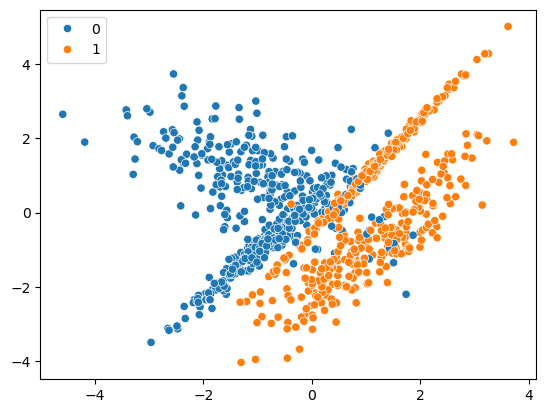

In [3]:
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y)

In [4]:
pd.Series(y).value_counts()

1    501
0    499
Name: count, dtype: int64

In [5]:
from sklearn.model_selection import train_test_split as tts
X_train,X_test,y_train,y_test=tts(X,y,random_state=42,test_size=0.2)

In [6]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((800, 2), (200, 2), (800,), (200,))

In [7]:
from sklearn.svm import SVC

In [8]:
svc=SVC(kernel='linear')

In [9]:
svc.fit(X_train,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [10]:
y_pred=svc.predict(X_test)


In [11]:
y_pred, y_test 

(array([0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
        1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1,
        1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
        1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0,
        0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
        1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0,
        0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1,
        0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0,
        0, 0]),
 array([0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
        1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1,
        1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
        1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 1, 1, 0,

In [12]:
## performance check 
from sklearn.metrics import classification_report, confusion_matrix

In [13]:
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.91      0.94        95
           1       0.92      0.98      0.95       105

    accuracy                           0.94       200
   macro avg       0.95      0.94      0.94       200
weighted avg       0.95      0.94      0.94       200

[[ 86   9]
 [  2 103]]


In [14]:
polynomial=SVC(kernel='poly')
polynomial.fit(X_train,y_train)
## Prediction
y_pred2=polynomial.predict(X_test)
print(classification_report(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.81      0.96      0.88        95
           1       0.95      0.80      0.87       105

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.87       200
weighted avg       0.89      0.88      0.87       200

[[91  4]
 [21 84]]


In [15]:
sigmoid=SVC(kernel='sigmoid')
sigmoid.fit(X_train,y_train)
## Prediction
y_pred3=sigmoid.predict(X_test)
print(classification_report(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))

              precision    recall  f1-score   support

           0       0.64      0.73      0.68        95
           1       0.72      0.63      0.67       105

    accuracy                           0.68       200
   macro avg       0.68      0.68      0.67       200
weighted avg       0.68      0.68      0.67       200

[[69 26]
 [39 66]]


## performance improvement by hyperparameter tuning 

In [16]:
from sklearn.model_selection import GridSearchCV

In [17]:
svc=SVC()

In [18]:
kernel=['linear', 'rbf', 'sigmoid']
gamma=[0.01,0.1,1,10,100,1000]
c=[0.01,0.1,1,10,100,1000]
params=dict(kernel=kernel,C=c,gamma=gamma)
params

{'kernel': ['linear', 'rbf', 'sigmoid'],
 'C': [0.01, 0.1, 1, 10, 100, 1000],
 'gamma': [0.01, 0.1, 1, 10, 100, 1000]}

In [19]:
grid=GridSearchCV(
    estimator=svc,
    param_grid=params,
    cv=5,
    verbose = 3,
    refit=True
)

In [20]:
grid.fit(X_train,y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
[CV 1/5] END .C=0.01, gamma=0.01, kernel=linear;, score=0.900 total time=   0.0s
[CV 2/5] END .C=0.01, gamma=0.01, kernel=linear;, score=0.912 total time=   0.0s
[CV 3/5] END .C=0.01, gamma=0.01, kernel=linear;, score=0.919 total time=   0.0s
[CV 4/5] END .C=0.01, gamma=0.01, kernel=linear;, score=0.938 total time=   0.0s
[CV 5/5] END .C=0.01, gamma=0.01, kernel=linear;, score=0.894 total time=   0.0s
[CV 1/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.500 total time=   0.0s
[CV 2/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.506 total time=   0.0s
[CV 3/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.506 total time=   0.0s
[CV 4/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.506 total time=   0.0s
[CV 5/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.506 total time=   0.0s
[CV 1/5] END C=0.01, gamma=0.01, kernel=sigmoid;, score=0.500 total time=   0.0s
[CV 2/5] END C=0.01, gamma=0.01, kernel=sigmoi

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'gamma': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [21]:
grid.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [22]:
grid.best_score_

0.9462499999999998

In [23]:
y_pred=grid.predict(X_test)

In [24]:
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.91      0.95        95
           1       0.92      1.00      0.96       105

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200

[[ 86   9]
 [  0 105]]


## from 68 it increased to 95 %